# FXS / 03f — Take-profit at +15 pips, no stop loss, time exit kept (EURUSD-01, EURUSD-02, USDJPY-01, USDJPY-02, 2016 → 2026)

Question (Iván, 2026-11-10): is the edge only **timing** (a small average drift over a fixed window) or a **real move** large enough to reach a consistent +15 pips?

Condition checked first (2026-11-10): 2026 trade swings were of the same size as 2016–2025 (EURUSD-02 st. dev. 16.5 pips vs 15.9–29.2; USDJPY-01 16.1 vs 7.5–23.7; USDJPY-02 18.0 vs 5.3–15.8), so the test is run.

| Version | Exit |
|---|---|
| `BASE` | scheduled end time only |
| `TP15` | **+15 pips take-profit**, otherwise the scheduled end time; **no stop loss** |

Plus two diagnostics (reported, not a rule choice):
- **Excursions:** in each `BASE` trade, how often the price went **+15 pips in favour** vs **−15 pips against** at any minute of the window. A real directional move shows clearly more favourable than adverse touches; pure timing noise shows about the same.
- **Take-profit ladder:** +10, +15, +20, +25, +30 pips, to see whether any level holds across periods.

Fills, costs and account as 03d/03e (minute bid/ask highs and lows; a minute that could hit both a stop and the take-profit counts against you; take-profit filled at the level, or at a better open). Periods: 2016–2020 (in sample), 2021–2025, 2026 (seen). Descriptive.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

E0 = 6_000.0
LEVERAGES = [1, 2, 3, 5, 10]
COMMISSION_PER_LOT = 3.0          # USD per lot, round trip
SPREAD_FACTOR = 0.9               # x Dukascopy spread
IDS = ["EURUSD-01", "EURUSD-02", "USDJPY-01", "USDJPY-02"]
FROZEN = {"EURUSD-01": ("UTC", 75, 195, 1), "EURUSD-02": ("NY", 660, 900, -1),
          "USDJPY-01": ("UTC", 55, 115, -1), "USDJPY-02": ("UTC", 25, 55, 1)}
WINDOWS = ((dt.date(2016, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
           (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
PERIODS = {"2016-2020 (in sample)": (2016, 2020), "2021-2025": (2021, 2025), "2026": (2026, 2026)}

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs03f_")
    os.environ.pop("DUKASCOPY_DIR", None)
    LEVERAGES = [1, 5]
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
TP_LADDER = [10.0, 15.0, 20.0, 25.0, 30.0]
VARIANTS = {"BASE": (F.NO_STOP, True), "TP15": (F.take_profit_only(15.0), True)}
LADDER = {f"TP{int(t)}": (F.take_profit_only(t), True) for t in TP_LADDER}
BRANCH = Path.cwd().parent
OUT = Path.cwd() / ("03f_synthetic" if SYNTHETIC else "03f"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 220, "display.max_columns", 40)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(("EURUSD", "USDJPY")):
        F.write_synthetic_candles(base, p, dt.date(2015, 12, 28), dt.date(2026, 11, 6), seed=11 + i, drift_bps=-3.0 if p == "EURUSD" else 0.0,
                                  drift_ny=(4, 8), price=150.0 if p.endswith("JPY") else 1.10)
    cand = pd.DataFrame([{"id": k, "pair": k[:6], "clock": c, "start": s, "end": e, "direction": d} for k, (c, s, e, d) in FROZEN.items()])
else:
    cand = F.load_frozen_candidates(BRANCH).query("id in @IDS").reset_index(drop=True)
for _, r in cand.iterrows():
    assert (r["clock"], int(r["start"]), int(r["end"]), int(r["direction"])) == FROZEN[r["id"]], f"{r['id']} is not the frozen rule"
cand = cand.set_index("id").loc[IDS].reset_index()
display(cand[["id", "pair", "clock", "start", "end", "direction"]].assign(
    rule=[f"{'buy' if d > 0 else 'sell'} {F.slot_label(c, s)} -> {F.slot_label(c, e)}" for c, s, e, d in zip(cand["clock"], cand["start"], cand["end"], cand["direction"])]))

,id,pair,clock,start,end,direction,rule
0,EURUSD-01,EURUSD,UTC,75,195,1,buy UTC 01:15 -> UTC 03:15
1,EURUSD-02,EURUSD,NY,660,900,-1,sell NY 04:00 -> NY 08:00
2,USDJPY-01,USDJPY,UTC,55,115,-1,sell UTC 00:55 -> UTC 01:55
3,USDJPY-02,USDJPY,UTC,25,55,1,buy UTC 00:25 -> UTC 00:55


## 1. Minute data (bid/ask open-high-low-close), 2015-12-31 → 2026-11-06

In [3]:
PAIRS = sorted(set(cand["pair"]))
minutes, days = {}, {}
for p in PAIRS:
    parts = [F.load_minutes_ohlc(p, a, b, st, cfg.min_file_share) for a, b, st in WINDOWS]
    m = pd.concat(parts)
    minutes[p] = F.scale_spread(m[~m.index.duplicated(keep="first")].sort_index(), SPREAD_FACTOR)
    for c in set(cand.loc[cand["pair"] == p, "clock"]):
        days[(p, c)] = np.concatenate([F.build_panel(F.load_minutes(p, a, b, st, min_file_share=cfg.min_file_share), p, c, a, b, cfg.min_coverage).dates
                                       for a, b, st in WINDOWS])
    print(p, len(minutes[p]), "minutes", minutes[p].index[0], "->", minutes[p].index[-1])

EURUSD 5708160 minutes 2015-12-31 00:00:00+00:00 -> 2026-11-06 23:59:00+00:00
USDJPY 5708160 minutes 2015-12-31 00:00:00+00:00 -> 2026-11-06 23:59:00+00:00


## 2. Every trade, both ways (and the take-profit ladder)

In [4]:
trades = []
for _, r in cand.iterrows():
    for v, (rule, time_exit) in VARIANTS.items():
        t = F.run_structure(minutes[r["pair"]], r["pair"], r["clock"], int(r["start"]), int(r["end"]), int(r["direction"]),
                            days[(r["pair"], r["clock"])], rule, time_exit, COMMISSION_PER_LOT)
        trades.append(t.assign(structure=r["id"], variant=v))
    for v, (rule, time_exit) in LADDER.items():
        if v in VARIANTS:
            continue
        t = F.run_structure(minutes[r["pair"]], r["pair"], r["clock"], int(r["start"]), int(r["end"]), int(r["direction"]),
                            days[(r["pair"], r["clock"])], rule, time_exit, COMMISSION_PER_LOT)
        trades.append(t.assign(structure=r["id"], variant=v))
trades = pd.concat(trades, ignore_index=True)
ladder = trades.copy()
trades = trades[trades["variant"].isin(list(VARIANTS))].reset_index(drop=True)
trades["year"] = pd.to_datetime(trades["date"]).dt.year
trades.to_parquet(OUT / "03f_trades.parquet")
print(trades.groupby(["variant", "structure"]).size().unstack())

structure  EURUSD-01  EURUSD-02  USDJPY-01  USDJPY-02
variant                                              
BASE            2816       2816       2816       2816
TP15            2816       2816       2816       2816


## 3. Per structure: pips, win rate, how trades end, how long they last

In [5]:
def per_structure(t):
    reasons = t["reason"].value_counts(normalize=True)
    return pd.Series({"trades": len(t), "net pips/trade": t["net_pips"].mean(), "win rate": (t["net_pips"] > 0).mean(),
                      "avg win pips": t.loc[t["net_pips"] > 0, "net_pips"].mean(), "avg loss pips": t.loc[t["net_pips"] <= 0, "net_pips"].mean(),
                      "% take-profit": reasons.get("tp", 0.0),
                      "% time / data end": reasons.get("time", 0.0) + reasons.get("end_of_data", 0.0),
                      "median minutes held": t["minutes"].median(), "max hours held": t["minutes"].max() / 60,
                      "worst trade pips": t["net_pips"].min(), "best trade pips": t["net_pips"].max()})
tab = trades.groupby(["structure", "variant"]).apply(per_structure)
display(tab.round(2)); tab.to_csv(OUT / "03f_per_structure.csv")

trades  net pips/trade  win rate  avg win pips  avg loss pips  % take-profit  % time / data end  median minutes held  max hours held  worst trade pips  best trade pips
structure variant                                                                                                                                                                         
EURUSD-01 BASE     2816.0            0.20      0.50          7.15          -6.83           0.00               1.00                120.0             2.0           -170.58           171.25
          TP15     2816.0            0.09      0.51          6.74          -6.71           0.11               0.89                120.0             2.0            -81.24            14.82
EURUSD-02 BASE     2816.0            1.78      0.53         16.77         -15.41           0.00               1.00                240.0             4.0           -117.45           148.97
          TP15     2816.0            0.90      0.60         12.24         -15.81           0.44               0.56                240.0             4.0           -117.45            15.23
USDJPY-01 BASE     2816.0            1.04      0.53         11.38         -10.67           0.00               1.00                 60.0             1.0           -206.50           187.07
          TP15     2816.0            0.72      0.56          9.49         -10.44           0.27               0.73                 60.0             1.0           -109.20            14.82
USDJPY-02 BASE     2816.0            0.59      0.53          8.44          -8.17           0.00               1.00                 30.0             0.5           -203.28           100.90
          TP15     2816.0            0.23      0.54          7.49          -8.16           0.14               0.86                 30.0             0.5           -203.28            14.70

## 3b. Net pips per trade by period

In [6]:
trades["period"] = None
for name, (a, b) in PERIODS.items():
    trades.loc[trades["year"].between(a, b), "period"] = name
per = trades.pivot_table(index=["structure", "variant"], columns="period", values="net_pips", aggfunc="mean")[list(PERIODS)]
wins = trades.assign(win=trades["net_pips"] > 0).pivot_table(index=["structure", "variant"], columns="period", values="win", aggfunc="mean")[list(PERIODS)]
display(per.round(2)); display((100 * wins).round(1).add_suffix(" win %"))
per.to_csv(OUT / "03f_period_pips.csv")

period             2016-2020 (in sample)  2021-2025  2026
structure variant                                        
EURUSD-01 BASE                      0.84      -0.10 -1.79
          TP15                      0.67      -0.19 -1.66
EURUSD-02 BASE                      2.20       1.54  0.71
          TP15                      0.63       1.16  0.97
USDJPY-01 BASE                      1.40       0.97 -0.69
          TP15                      0.96       0.72 -0.65
USDJPY-02 BASE                      0.52       0.81 -0.21
          TP15                      0.28       0.30 -0.53

period             2016-2020 (in sample) win %  2021-2025 win %  2026 win %
structure variant                                                          
EURUSD-01 BASE                            52.9             49.1        42.5
          TP15                            53.2             49.3        42.5
EURUSD-02 BASE                            54.0             52.8        53.8
          TP15                            60.1             59.4        57.9
USDJPY-01 BASE                            53.9             53.7        44.8
          TP15                            55.5             57.8        48.4
USDJPY-02 BASE                            51.5             53.9        53.8
          TP15                            51.8             55.2        54.8

## 3c. Timing or a real move? Favourable vs adverse excursions in BASE trades

Share of trades that touched **+15 pips in favour** and **−15 pips against** at some minute of the window (after the spread at entry), by period; and the median best and worst point.

In [7]:
b = trades[trades["variant"] == "BASE"].copy()
b["fav15"], b["adv15"] = b["best_pips"] >= 15, b["worst_pips"] <= -15
exc = b.groupby(["structure", "period"]).agg(trades=("net_pips", "size"), touched_plus15=("fav15", "mean"), touched_minus15=("adv15", "mean"),
                                             median_best=("best_pips", "median"), median_worst=("worst_pips", "median"))
exc["plus15 minus minus15 (pp)"] = 100 * (exc["touched_plus15"] - exc["touched_minus15"])
exc[["touched_plus15", "touched_minus15"]] *= 100
exc = exc.reindex(pd.MultiIndex.from_product([IDS, list(PERIODS)], names=["structure", "period"]))
display(exc.round(1)); exc.to_csv(OUT / "03f_excursions.csv")

trades  touched_plus15  touched_minus15  median_best  median_worst  plus15 minus minus15 (pp)
structure period                                                                                                              
EURUSD-01 2016-2020 (in sample)    1297            12.0              8.4          5.4          -5.1                        3.6
          2021-2025                1298            10.2             11.9          5.3          -5.9                       -1.7
          2026                      221             5.4              9.5          4.5          -5.8                       -4.1
EURUSD-02 2016-2020 (in sample)    1297            46.4             42.6         13.8         -12.3                        3.9
          2021-2025                1298            42.9             41.8         12.7         -12.2                        1.2
          2026                      221            34.8             27.1         11.3          -8.5                        7.7
USDJPY-01 2016-2020 (in sample)    1297            21.4             17.0          7.0          -6.0                        4.5
          2021-2025                1298            33.7             27.5          9.9          -7.8                        6.2
          2026                      221            25.8             19.9          7.8          -8.4                        5.9
USDJPY-02 2016-2020 (in sample)    1297             9.3              8.9          5.3          -4.8                        0.3
          2021-2025                1298            19.3             18.0          6.7          -6.5                        1.2
          2026                      221            14.0             14.9          6.6          -5.2                       -0.9

## 3d. Take-profit ladder: net pips per trade and hit rate, by period (reported, not a rule choice)

In [8]:
ladder["period"] = None
for name, (a, b_) in PERIODS.items():
    ladder.loc[pd.to_datetime(ladder["date"]).dt.year.between(a, b_), "period"] = name
lad = ladder.pivot_table(index=["structure", "variant"], columns="period", values="net_pips", aggfunc="mean")[list(PERIODS)]
hit = ladder.assign(h=ladder["reason"] == "tp").pivot_table(index=["structure", "variant"], columns="period", values="h", aggfunc="mean")[list(PERIODS)]
order = ["BASE"] + [f"TP{int(t)}" for t in TP_LADDER]
lad = lad.reindex(pd.MultiIndex.from_product([IDS, order]))
hit = (100 * hit).reindex(pd.MultiIndex.from_product([IDS, order]))
display(lad.round(2)); display(hit.round(1).add_suffix(" TP hit %"))
lad.to_csv(OUT / "03f_ladder_pips.csv"); hit.to_csv(OUT / "03f_ladder_hits.csv")

period          2016-2020 (in sample)  2021-2025  2026
EURUSD-01 BASE                   0.84      -0.10 -1.79
          TP10                   0.58       0.01 -1.54
          TP15                   0.67      -0.19 -1.66
          TP20                   0.77      -0.03 -1.62
          TP25                   0.88      -0.04 -1.75
          TP30                   0.95      -0.04 -1.73
EURUSD-02 BASE                   2.20       1.54  0.71
          TP10                   0.31       1.13  0.46
          TP15                   0.63       1.16  0.97
          TP20                   1.14       1.38  1.27
          TP25                   1.59       1.08  1.43
          TP30                   1.70       1.14  1.55
USDJPY-01 BASE                   1.40       0.97 -0.69
          TP10                   0.77       0.59 -0.78
          TP15                   0.96       0.72 -0.65
          TP20                   1.04       0.91 -0.39
          TP25                   1.14       1.12  0.04
          TP30                   1.10       1.07 -0.61
USDJPY-02 BASE                   0.52       0.81 -0.21
          TP10                   0.26       0.36 -0.44
          TP15                   0.28       0.30 -0.53
          TP20                   0.34       0.47 -0.56
          TP25                   0.41       0.62 -0.28
          TP30                   0.43       0.67 -0.33

period          2016-2020 (in sample) TP hit %  2021-2025 TP hit %  2026 TP hit %
EURUSD-01 BASE                             0.0                 0.0            0.0
          TP10                            25.9                24.5           14.9
          TP15                            12.0                10.2            5.4
          TP20                             6.2                 5.4            3.2
          TP25                             4.0                 2.6            0.5
          TP30                             2.7                 1.3            0.5
EURUSD-02 BASE                             0.0                 0.0            0.0
          TP10                            63.1                60.6           54.8
          TP15                            46.4                42.9           34.8
          TP20                            34.5                29.7           21.7
          TP25                            26.6                19.4           14.9
          TP30                            18.8                13.7            8.6
USDJPY-01 BASE                             0.0                 0.0            0.0
          TP10                            35.9                49.5           42.1
          TP15                            21.4                33.7           25.8
          TP20                            12.5                23.6           19.0
          TP25                             7.9                17.0           14.0
          TP30                             4.2                11.9            8.1
USDJPY-02 BASE                             0.0                 0.0            0.0
          TP10                            22.6                33.9           33.5
          TP15                             9.3                19.3           14.0
          TP20                             4.5                10.2            6.8
          TP25                             2.1                 5.7            5.4
          TP30                             1.2                 3.2            1.8

## 4. Net pips per trade, year by year

structure EURUSD-01       EURUSD-02       USDJPY-01       USDJPY-02      
variant        BASE  TP15      BASE  TP15      BASE  TP15      BASE  TP15
year                                                                     
2016           0.64  0.58      3.37 -0.14      0.83  0.53     -0.13 -0.26
2017           0.93  1.17      2.77  1.24      1.34  1.27      0.85  0.74
2018           0.84  0.27      2.46  0.48      1.22  0.78      0.99  0.87
2019           0.41  0.45      1.87  1.11      0.58  0.73      0.30  0.19
2020           1.39  0.91      0.55  0.49      2.99  1.46      0.58 -0.11
2021           0.13  0.03      1.84  1.94      0.46  0.61      0.89  0.87
2022           0.02 -0.13      4.15  2.18      1.81  1.25      2.24  1.35
2023           0.12 -0.04      1.27  0.72      0.37 -0.29      0.08  0.11
2024          -0.53 -0.57      0.27 -0.05      0.86  1.04      0.97  0.06
2025          -0.23 -0.22      0.14  1.00      1.34  1.00     -0.16 -0.89
2026          -1.79 -1.66      0.71  0.97     -0.69 -0.65     -0.21 -0.53

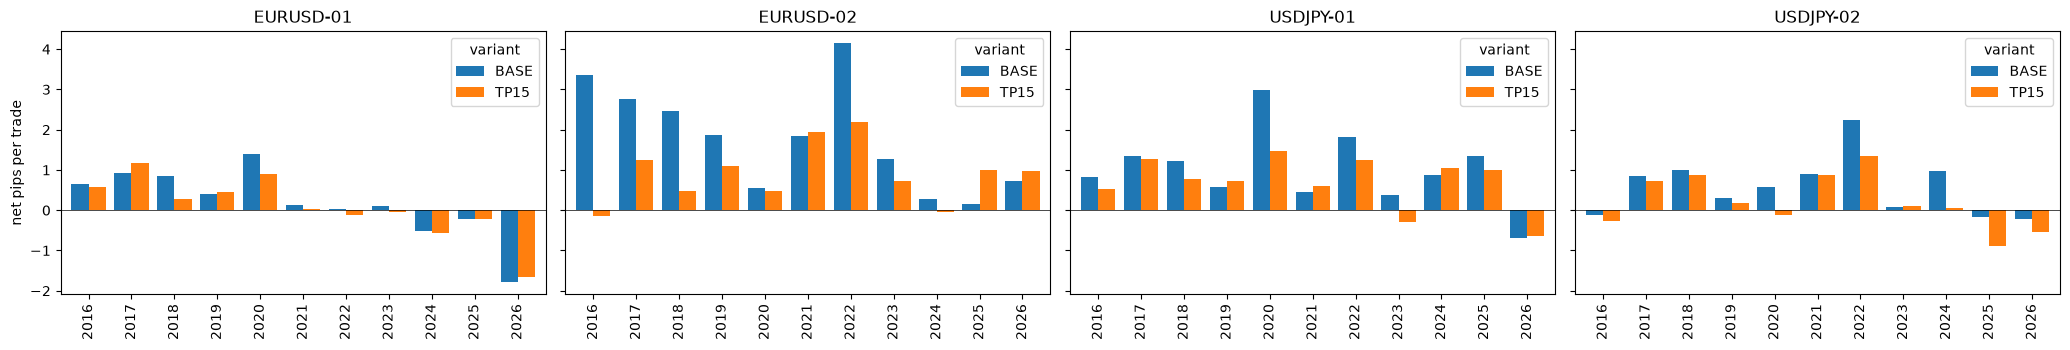

In [9]:
yr = trades.pivot_table(index="year", columns=["structure", "variant"], values="net_pips", aggfunc="mean")
display(yr.round(2)); yr.to_csv(OUT / "03f_yearly_pips.csv")
fig, axes = plt.subplots(1, len(IDS), figsize=(5.2 * len(IDS), 3.6), sharey=True)
for ax, i in zip(axes, IDS):
    yr[i].plot.bar(ax=ax, width=0.8); ax.axhline(0, color="black", lw=0.5); ax.set_title(i); ax.set_xlabel("")
axes[0].set_ylabel("net pips per trade")
plt.tight_layout(); plt.savefig(OUT / "03f_yearly_pips.png", dpi=110); plt.show()

## 5. The compounding account: all four structures together, from $6,000

Equity is realised at each trade's exit.

,variant,L each,final_equity,cagr,ann_vol,sharpe,max_drawdown,worst_year,best_year,ruined
0,BASE,1,13694.0,7.9%,4.4%,1.712426,-7.3%,-3.1%,19.3%,False
1,BASE,2,32331.0,16.8%,9.0%,1.726873,-14.4%,-6.6%,43.2%,False
2,BASE,3,74573.0,26.2%,13.6%,1.729123,-21.3%,-10.0%,71.1%,False
3,BASE,5,365326.0,46.1%,22.8%,1.728070,-33.9%,-16.6%,140.9%,False
4,BASE,10,13118881.0,103.3%,45.8%,1.728767,-59.2%,-32.8%,432.6%,False
5,TP15,1,9344.0,4.2%,3.2%,1.245038,-4.9%,-2.8%,10.1%,False
6,TP15,2,14802.0,8.7%,6.8%,1.225088,-10.0%,-6.0%,21.8%,False
7,TP15,3,23332.0,13.3%,10.3%,1.232299,-15.0%,-9.0%,34.6%,False
8,TP15,5,54842.0,22.6%,17.3%,1.231513,-24.5%,-14.9%,63.5%,False
9,TP15,10,362904.0,46.0%,34.8%,1.231505,-46.0%,-29.3%,161.7%,False


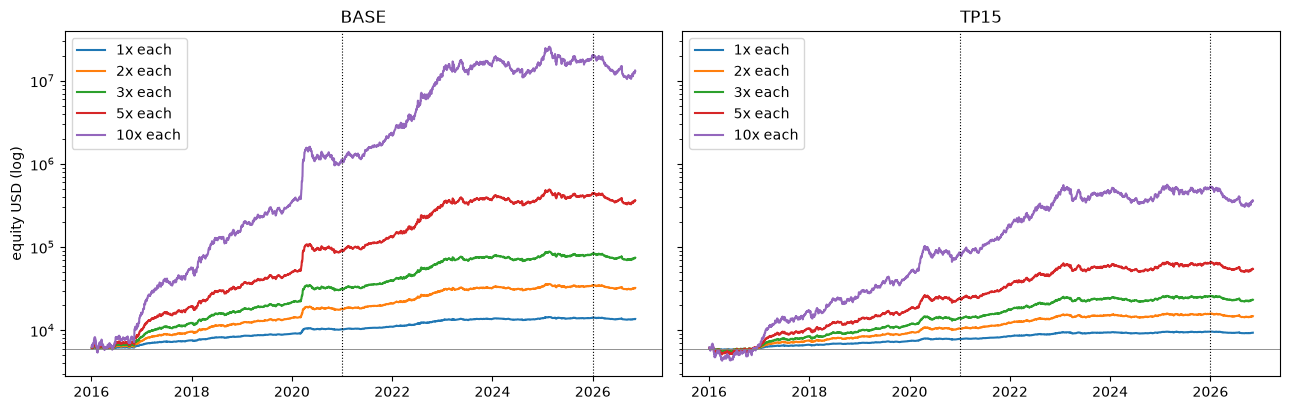

In [10]:
rows, curves = [], {}
for v in VARIANTS:
    tv = trades[trades["variant"] == v]
    for L in LEVERAGES:
        acc = F.simulate_events(tv, L, E0)
        curves[(v, L)] = acc
        rows.append({"variant": v, "L each": L, **F.account_stats(acc, E0)})
res = pd.DataFrame(rows)
show = res.copy()
for c in ("cagr", "ann_vol", "max_drawdown", "worst_year", "best_year"):
    show[c] = (100 * show[c]).round(1).astype(str) + "%"
show["final_equity"] = show["final_equity"].round(0)
display(show); res.to_csv(OUT / "03f_account.csv", index=False)
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(13, 4.2), sharey=True)
for ax, v in zip(axes, VARIANTS):
    for L in LEVERAGES:
        ax.plot(curves[(v, L)]["equity"].clip(lower=1), label=f"{L}x each")
    ax.axhline(E0, color="grey", lw=0.6)
    for b in ("2021-01-01", "2026-01-01"):
        ax.axvline(pd.Timestamp(b), color="black", ls=":", lw=0.8)
    ax.set_yscale("log"); ax.set_title(v); ax.legend()
axes[0].set_ylabel("equity USD (log)")
plt.tight_layout(); plt.savefig(OUT / "03f_equity.png", dpi=110); plt.show()

## 5b. Annual return within each period (separate $6,000 accounts started at each period's first day)

In [11]:
pr = []
for v in VARIANTS:
    for name, (a, b) in PERIODS.items():
        tv = trades[(trades["variant"] == v) & trades["year"].between(a, b)]
        for L in LEVERAGES:
            st = F.account_stats(F.simulate_events(tv, L, E0), E0)
            pr.append({"variant": v, "period": name, "L": L, "cagr %": round(100 * st["cagr"], 1), "max dd %": round(100 * st["max_drawdown"], 1)})
pr = pd.DataFrame(pr)
display(pr.pivot_table(index=["variant", "L"], columns="period", values=["cagr %", "max dd %"])[[("cagr %", p) for p in PERIODS] + [("max dd %", p) for p in PERIODS]])
pr.to_csv(OUT / "03f_period_account.csv", index=False)

cagr %                              max dd %                
period     2016-2020 (in sample) 2021-2025  2026 2016-2020 (in sample) 2021-2025  2026
variant L                                                                             
BASE    1                   11.4       6.4  -3.5                  -4.4      -4.8  -5.2
        2                   24.8      13.7  -7.8                  -8.8     -10.0 -11.4
        3                   39.5      20.9 -11.5                 -13.3     -15.0 -16.7
        5                   72.9      36.3 -19.3                 -21.6     -24.2 -27.0
        10                 184.9      77.3 -37.5                 -40.3     -44.0 -48.3
TP15    1                    5.6       3.9  -3.1                  -4.0      -4.3  -4.4
        2                   11.9       8.4  -6.9                  -8.4      -8.3  -9.7
        3                   18.6      12.7 -10.3                 -12.5     -12.5 -14.4
        5                   32.3      21.5 -17.2                 -20.4     -20.8 -23.3
        10                  70.0      43.3 -33.6                 -37.7     -40.0 -42.6

## 6. Account return year by year (%)

In [12]:
def yearly_returns(acc):
    y = acc["equity"].resample("YE").last()
    r = y.pct_change(); r.iloc[0] = y.iloc[0] / E0 - 1
    r.index = r.index.year
    return r
yrs = pd.DataFrame({(v, f"{L}x"): yearly_returns(curves[(v, L)]) for v in VARIANTS for L in LEVERAGES})
display((100 * yrs).round(1)); yrs.to_csv(OUT / "03f_yearly_returns.csv")

BASE                            TP15                         
        1x    2x    3x     5x    10x    1x    2x    3x    5x    10x
2016  11.3  23.5  37.5   67.2  158.9   1.3   3.1   4.6   7.0    9.3
2017  13.3  29.9  48.3   92.6  259.5  10.1  21.7  34.6  63.5  161.7
2018  12.1  26.7  42.7   80.0  211.5   4.9  10.8  16.9  29.2   62.4
2019   7.0  15.1  23.9   42.3   98.2   5.7  11.6  18.1  31.7   70.7
2020  13.4  29.1  46.3   86.4  223.5   6.1  13.1  20.6  35.7   78.2
2021   7.1  15.4  24.1   42.9  100.1   7.6  16.2  25.2  45.4  108.1
2022  19.3  43.2  71.1  140.9  432.6  10.0  21.8  34.5  62.8  153.9
2023   3.9   7.8  11.6   18.8   33.9   1.0   1.7   2.4   3.4    3.3
2024   2.3   4.5   6.6   10.4   16.6   0.3   0.4   0.5   0.5   -1.6
2025   1.1   2.6   3.7    5.2    5.3   1.8   3.4   5.2   8.1   12.7
2026  -3.1  -6.6 -10.0  -16.6  -32.8  -2.8  -6.0  -9.0 -14.9  -29.3

## 7. The same accounts without EURUSD-01 (the 03b set)

EURUSD-01 failed its 2021–2025 confirmation; this shows what including it costs.

In [13]:
rows3 = []
for v in VARIANTS:
    tv = trades[(trades["variant"] == v) & (trades["structure"] != "EURUSD-01")]
    for L in LEVERAGES:
        st = F.account_stats(F.simulate_events(tv, L, E0), E0)
        rows3.append({"variant": v, "L each": L, "final_equity": round(st["final_equity"]), "cagr %": round(100 * st["cagr"], 1),
                      "max drawdown %": round(100 * st["max_drawdown"], 1), "worst year %": round(100 * st["worst_year"], 1)})
display(pd.DataFrame(rows3)); pd.DataFrame(rows3).to_csv(OUT / "03f_account_without_EURUSD01.csv", index=False)

,variant,L each,final_equity,cagr %,max drawdown %,worst year %
0,BASE,1,12988,7.4,-5.1,-0.2
1,BASE,2,29278,15.7,-10.5,0.0
2,BASE,3,64774,24.5,-15.6,-0.2
3,BASE,5,296479,43.3,-25.0,-0.8
4,BASE,10,9369958,97.1,-45.0,-4.4
5,TP15,1,9089,3.9,-3.6,0.0
6,TP15,2,14232,8.3,-7.4,0.2
7,TP15,3,21909,12.7,-11.2,0.2
8,TP15,5,49821,21.6,-18.4,-0.0
9,TP15,10,320047,44.3,-34.7,-3.7


In [14]:
summary = {"study": "FXS03f", "descriptive": True, "synthetic": SYNTHETIC, "structures": IDS, "equity0": E0,
           "take_profit_pips": 15.0, "ladder": TP_LADDER,
           "commission_usd_per_lot_rt": COMMISSION_PER_LOT, "spread_factor": SPREAD_FACTOR,
           "per_structure": tab.round(4).reset_index().to_dict(orient="records"), "account": res.to_dict(orient="records"),
           "note": "Take-profit chosen after seeing the data; hindsight structure set; 2026 already seen."}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\03f\summary.json
